In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [72]:
hitters = pd.read_parquet('hitter_agg.parquet')

In [73]:
hitters.columns

Index(['Batter', 'BatterTeam', 'pitches_seen', 'swings', 'whiffs',
       'chase_swings', 'foul_balls', 'balls_in_play', 'called_strikes',
       'swinging_strikes', 'zone_rate', 'swing_rate', 'whiff_rate',
       'chase_rate', 'in_play_rate', 'contact_rate', 'sweet_spot_rate',
       'gb_rate', 'ld_rate', 'fb_rate', 'pu_rate', 'zone_swings',
       'zone_swing_rate', 'zone_contact', 'zone_contact_rate', 'avg_exit_velo',
       'avg_launch_angle', 'avg_direction', 'avg_batspeed', 'max_ev', 'ev_95',
       'barrel_rate', 'xDamage', 'xwOBA', 'xSLG', 'xBA', 'plate_appearances',
       'strikeouts', 'walks', 'strikeout_rate', 'walk_rate', 'home_runs',
       'at_bats', 'hr_per_ab', 'singles', 'doubles', 'triples', 'hits',
       'total_bases', 'iso', 'tto_rate', 'avg', 'babip', 'obp', 'slg', 'ops',
       'pull_air_bbe', 'total_bbe', 'pull_air_pct', 'Year',
       'natural_attack_angle', 'natural_max_ev', 'natural_method'],
      dtype='object')

In [74]:
min_val = 100

In [75]:
min_var = 'total_bbe'

In [76]:
hpa = hitters[hitters[min_var] >= min_val]

In [77]:
corr = hpa[['babip', 'avg_launch_angle', 'sweet_spot_rate','avg', 'barrel_rate', 'xBA', 'slg', 'xSLG', 'xwOBA', 'xDamage', 'avg_exit_velo', 'natural_attack_angle', 'gb_rate', 'fb_rate', 'pu_rate']].corr()

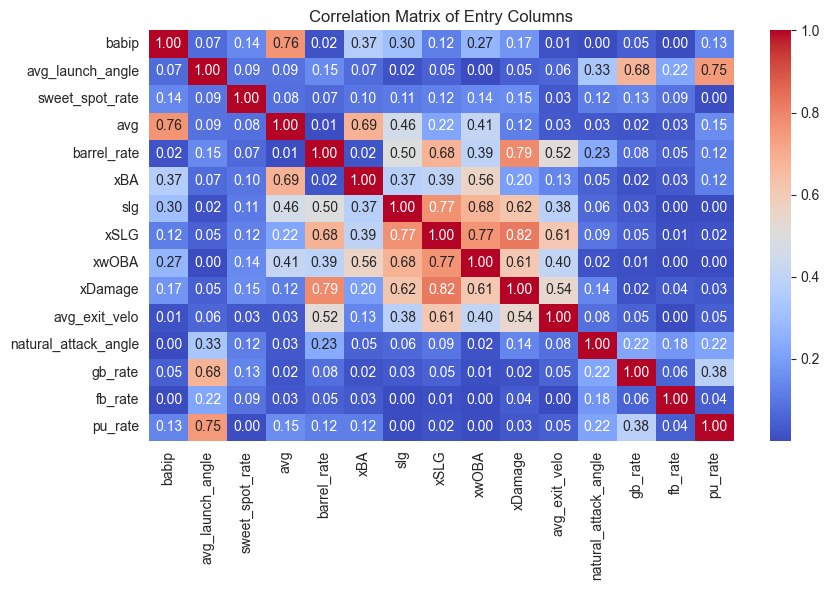

In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
sns.heatmap(corr**2, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Entry Columns")
plt.tight_layout()
plt.show()


In [79]:
corr = hpa[['iso', 'babip', 'avg_exit_velo', 'natural_attack_angle', 'avg_launch_angle', 'natural_max_ev', 'max_ev', 'ev_95', 'zone_swing_rate', 'sweet_spot_rate', 'barrel_rate']].corr()

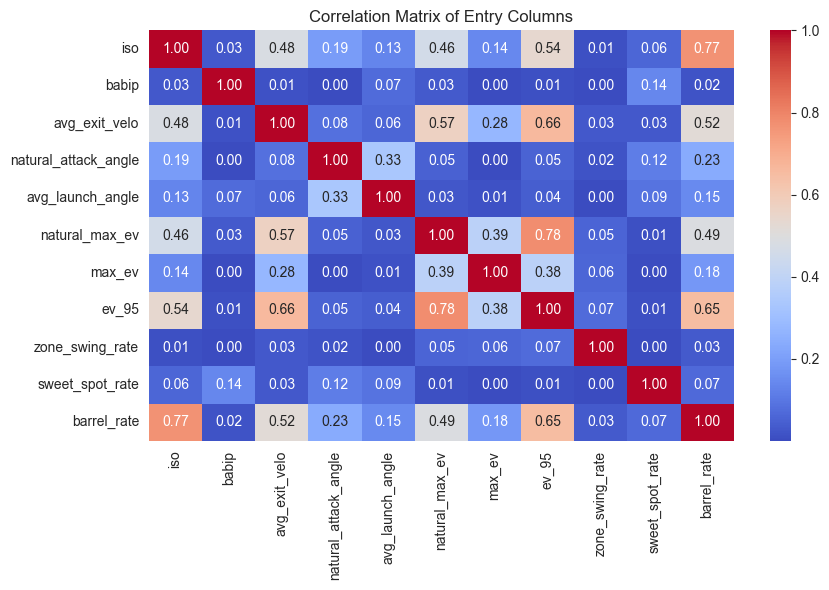

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
sns.heatmap(corr**2, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Entry Columns")
plt.tight_layout()
plt.show()


In [91]:
corr = hpa[['ops', 'avg', 'obp', 'slg', 'iso', 'babip', 'strikeout_rate', 'walk_rate', 'barrel_rate', 'gb_rate', 'sweet_spot_rate']].corr()

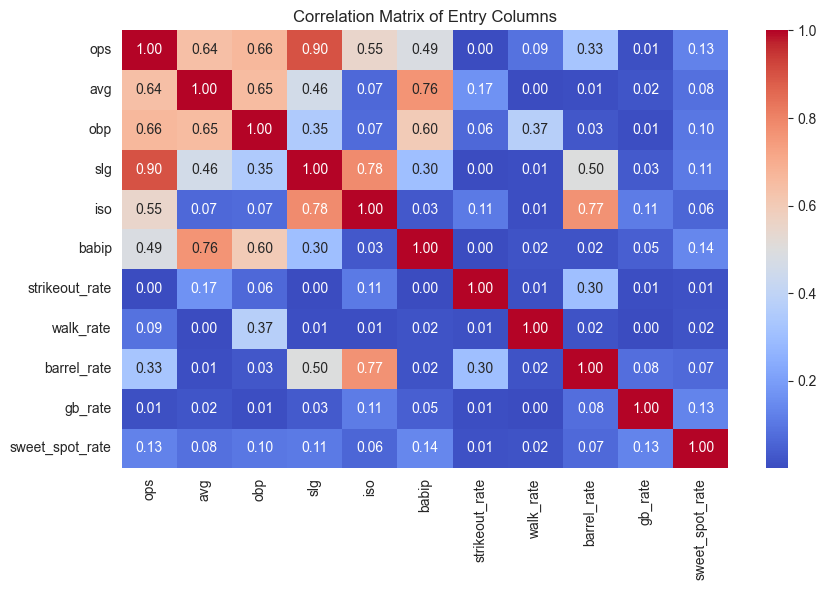

In [93]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
sns.heatmap(corr**2, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Entry Columns")
plt.tight_layout()
plt.show()

In [94]:
hpa[['Batter', 'BatterTeam', 'barrel_rate', 'whiff_rate', 'strikeout_rate', 'xSLG', 'xDamage', 'xwOBA']].head()

,Batter,BatterTeam,barrel_rate,whiff_rate,strikeout_rate,xSLG,xDamage,xwOBA
2,"Acevedo, Luis",New Jersey Jackals,0.026316,0.137349,0.112628,0.395438,0.356890,0.353999
5,"Agresti, Jason",New York Boulders,0.073643,0.207273,0.159159,0.465470,0.402238,0.358134
8,"Alvarez, Jose",Gateway Grizzlies,0.016327,0.182495,0.138264,0.395688,0.375890,0.347706
18,"Backstrom, Mahki",Sussex County Miners,0.121547,0.326255,0.228873,0.570029,0.511598,0.420992
22,"Ballard, Michael",Florence Y'alls,0.061350,0.171091,0.164319,0.442544,0.380313,0.339762


(array([28., 30., 30., 36., 25., 10., 11.,  2.,  4.,  1.]),
 array([0.        , 0.01860465, 0.0372093 , 0.05581395, 0.0744186 ,
        0.09302326, 0.11162791, 0.13023256, 0.14883721, 0.16744186,
        0.18604651]),
 <BarContainer object of 10 artists>)

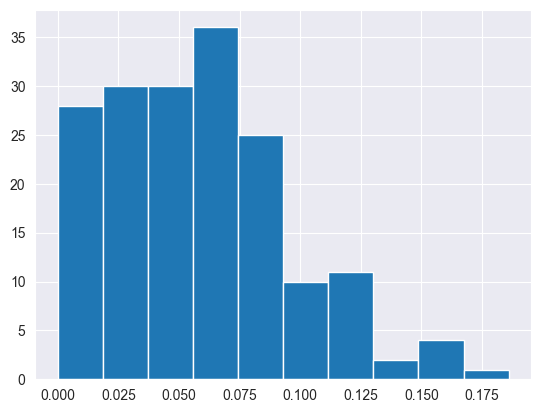

In [95]:
plt.hist(hpa['barrel_rate'])

(array([ 3.,  7., 25., 22., 43., 32., 26., 14.,  2.,  3.]),
 array([0.20348837, 0.22890225, 0.25431612, 0.27973   , 0.30514387,
        0.33055775, 0.35597162, 0.38138549, 0.40679937, 0.43221324,
        0.45762712]),
 <BarContainer object of 10 artists>)

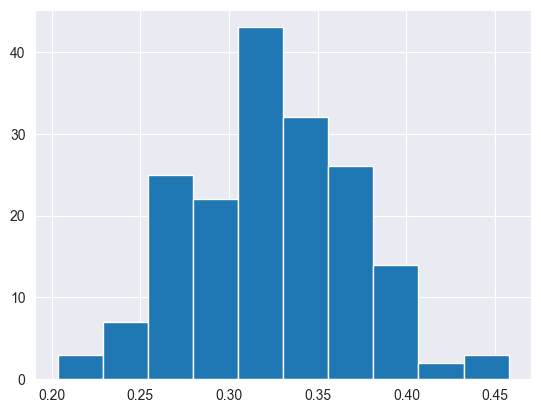

In [97]:
plt.hist(hpa['babip'])

In [98]:
hpa['babip'].describe()

count    177.000000
mean       0.323182
std        0.045912
min        0.203488
25%        0.290323
50%        0.321608
75%        0.356021
max        0.457627
Name: babip, dtype: float64

In [96]:
hpa['contact_rate'].corr(hpa['strikeout_rate'])

np.float64(-0.8703102602692551)

In [66]:
hpa['chase_rate'].corr(hpa['walk_rate'])

np.float64(-0.7743645741013052)

In [67]:
hpa['strikeout_rate'].corr(hpa['avg'])

np.float64(-0.4084923854650421)

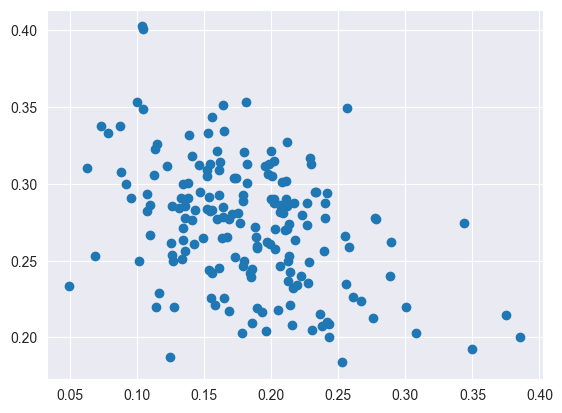

In [68]:
plt.scatter(hpa['strikeout_rate'], hpa['avg'])

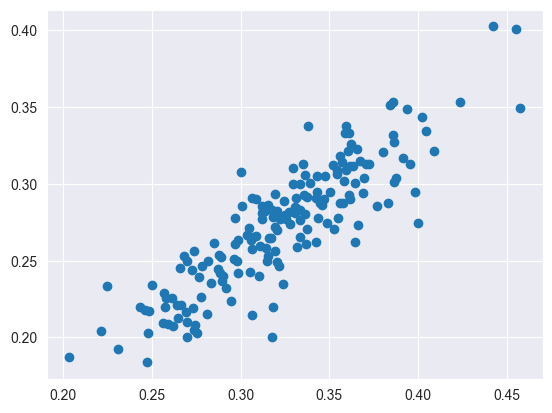

In [69]:
plt.scatter(hpa['babip'], hpa['avg'])

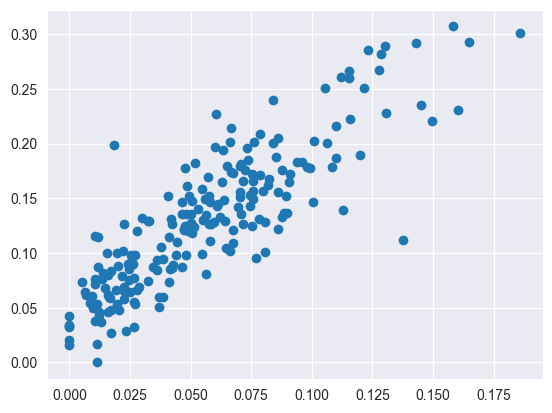

In [64]:
plt.scatter(hpa['barrel_rate'], hpa['iso'])

In [65]:
hpa['sqrt_k_rate'] = np.sqrt(hpa.loc[:,'strikeout_rate'])

C:\Users\215nt\AppData\Local\Temp\ipykernel_92792\3642904742.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hpa['sqrt_k_rate'] = np.sqrt(hpa.loc[:,'strikeout_rate'])


In [66]:
import statsmodels.api as sm


In [73]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# -----------------------------
# 1. Define X and y
# -----------------------------
X_raw = hpa[['ev_95', 'barrel_rate', 'gb_rate']].copy()
y = hpa['iso']

# -----------------------------
# 2. Train-test split
# -----------------------------
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.3, random_state=42
)

# -----------------------------
# 3. Scale (fit on train only)
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Rebuild DataFrames
X_train = pd.DataFrame(X_train_scaled, columns=X_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_raw.columns, index=X_test_raw.index)

# -----------------------------
# 4. Add intercept
# -----------------------------
X_train = sm.add_constant(X_train, has_constant='add')
X_test = sm.add_constant(X_test, has_constant='add')

# -----------------------------
# 5. Fit OLS on training set
# -----------------------------
model = sm.OLS(y_train, X_train)
results = model.fit()

print(results.summary())

# -----------------------------
# 6. Evaluate on test set
# -----------------------------
y_pred = results.predict(X_test)

test_r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nTest-set performance:")
print("R²:", test_r2)
print("MAE:", mae)
print("RMSE:", rmse)

# -----------------------------
# 7. K-fold cross-validation (manual for statsmodels)
# -----------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_r2 = []
cv_mae = []
cv_rmse = []

for train_idx, val_idx in kf.split(X_raw):
    X_tr, X_val = X_raw.iloc[train_idx], X_raw.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # scale inside each fold (fit on train only)
    scaler_cv = StandardScaler()
    X_tr_scaled = scaler_cv.fit_transform(X_tr)
    X_val_scaled = scaler_cv.transform(X_val)

    # rebuild DataFrames
    X_tr_df = pd.DataFrame(X_tr_scaled, columns=X_raw.columns, index=X_tr.index)
    X_val_df = pd.DataFrame(X_val_scaled, columns=X_raw.columns, index=X_val.index)

    # add intercept
    X_tr_df = sm.add_constant(X_tr_df, has_constant='add')
    X_val_df = sm.add_constant(X_val_df, has_constant='add')

    # fit model
    fold_model = sm.OLS(y_tr, X_tr_df).fit()

    # predict
    y_val_pred = fold_model.predict(X_val_df)

    # metrics
    cv_r2.append(r2_score(y_val, y_val_pred))
    cv_mae.append(mean_absolute_error(y_val, y_val_pred))
    cv_rmse.append(np.sqrt(mean_squared_error(y_val, y_val_pred)))

print("\nCross-validation results (5-fold):")
print("By fold:", cv_r2)
print("Mean R²:", np.mean(cv_r2))
print("Mean MAE:", np.mean(cv_mae))
print("Mean RMSE:", np.mean(cv_rmse))


                            OLS Regression Results                            
Dep. Variable:                    iso   R-squared:                       0.745
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     138.3
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           6.04e-42
Time:                        13:19:41   Log-Likelihood:                 295.85
No. Observations:                 146   AIC:                            -583.7
Df Residuals:                     142   BIC:                            -571.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.1316      0.003     49.153      

In [74]:
print("\nTest-set performance:")
print("R²:", test_r2)
print("MAE:", mae)
print("RMSE:", rmse)


Test-set performance:
R²: 0.7641283111662586
MAE: 0.024420574440199128
RMSE: 0.032011626611284136


In [75]:
print("\nCross-validation results (5-fold):")
print("By fold:", cv_r2)
print("Mean R²:", np.mean(cv_r2))
print("Mean MAE:", np.mean(cv_mae))
print("Mean RMSE:", np.mean(cv_rmse))


Cross-validation results (5-fold):
By fold: [0.7515167255946951, 0.7511060337053164, 0.6930907463539582, 0.7866138299895493, 0.6959493737336522]
Mean R²: 0.7356553418754342
Mean MAE: 0.025217468243201147
Mean RMSE: 0.03260949793444033


In [76]:
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    het_white,
    acorr_breusch_godfrey,
    linear_reset,
    normal_ad
)

# -----------------------------------------
# Standardized residuals (already computed)
# -----------------------------------------
std_resid = results.get_influence().resid_studentized_internal

# -----------------------------------------
# 1. Normality test (Anderson-Darling)
# -----------------------------------------
ad_stat, ad_p = normal_ad(std_resid)

print("\nNormality (Anderson-Darling):")
print(f"  AD stat = {ad_stat:.4f}, p = {ad_p:.4f}")

# -----------------------------------------
# 2. Homoskedasticity tests
# -----------------------------------------
bp_stat, bp_p, _, _ = het_breuschpagan(results.resid, results.model.exog)
white_stat, white_p, _, _ = het_white(results.resid, results.model.exog)

print("\nHomoskedasticity Tests:")
print(f"  Breusch-Pagan: stat = {bp_stat:.4f}, p = {bp_p:.4f}")
print(f"  White Test:    stat = {white_stat:.4f}, p = {white_p:.4f}")

# -----------------------------------------
# 3. Autocorrelation test (Breusch-Godfrey)
# -----------------------------------------
bg_stat, bg_p, _, _ = acorr_breusch_godfrey(results, nlags=5)

print("\nAutocorrelation (Breusch-Godfrey):")
print(f"  BG stat = {bg_stat:.4f}, p = {bg_p:.4f}")

# -----------------------------------------
# 4. Functional form test (RESET)
# -----------------------------------------
reset = linear_reset(results, power=2, use_f=True)

print("\nFunctional Form (RESET test):")
print(f"  F-stat = {reset.fvalue:.4f}, p = {reset.pvalue:.4f}")



Normality (Anderson-Darling):
  AD stat = 0.7636, p = 0.0461

Homoskedasticity Tests:
  Breusch-Pagan: stat = 5.6088, p = 0.1323
  White Test:    stat = 15.0408, p = 0.0898

Autocorrelation (Breusch-Godfrey):
  BG stat = 4.4169, p = 0.4911

Functional Form (RESET test):
  F-stat = 0.0016, p = 0.9684


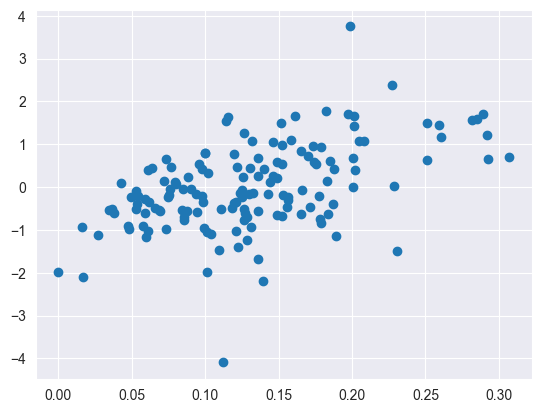

In [77]:
plt.scatter(y_train, std_resid)